In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


pd.set_option("display.max_columns", None)

data_path = r"C:\Users\main\Desktop\Projects\Retail Demand Forecasting"

excel_path = data_path + r"\data\retail_demand_forecasting_raw_data.xlsx"

df = pd.read_excel(excel_path, sheet_name="Raw_Data")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (200, 12)


In [3]:
df.head(5)

,Date,Store_ID,Product_ID,Product_Category,Units_Sold,Unit_Price_NPR,Discount_Pct,Promotion,Day_of_Week,Is_Holiday,Inventory_Level,Weather
0,2025-01-01,ST-01,SKU-1001,Beverages,46,116.88,10.0,Yes,Wednesday,0.0,72.0,Cool
1,2025-01-02,ST-01,SKU-1001,Beverages,42,116.09,10.0,Yes,Thursday,0.0,53.0,Cool
2,2025-01-03,ST-01,SKU-1001,Beverages,48,117.44,10.0,Yes,Friday,0.0,72.0,Cool
3,2025-01-04,ST-01,SKU-1001,Beverages,53,123.38,10.0,Yes,Saturday,0.0,58.0,Cool
4,2025-01-05,ST-01,SKU-1001,Beverages,47,117.12,0.0,No,Sunday,0.0,61.0,Cool


In [4]:
df.tail(5)

,Date,Store_ID,Product_ID,Product_Category,Units_Sold,Unit_Price_NPR,Discount_Pct,Promotion,Day_of_Week,Is_Holiday,Inventory_Level,Weather
195,2025-07-15,ST-01,SKU-1001,Beverages,48,119.76,0.0,No,Tuesday,0.0,74.0,Mild
196,2025-07-16,ST-01,SKU-1001,Beverages,38,120.75,0.0,No,Wednesday,0.0,51.0,Mild
197,2025-07-16,ST-01,SKU-1001,Beverages,33,119.55,0.0,No,Thursday,0.0,33.0,Cool
198,2025-07-18,ST-01,SKU-1001,Beverages,28,121.17,0.0,No,Friday,0.0,42.0,Mild
199,2025-07-19,ST-01,SKU-1001,Beverages,49,123.18,0.0,No,Saturday,0.0,64.0,Mild


In [5]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 200
Total Columns: 12


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              200 non-null    str    
 1   Store_ID          200 non-null    str    
 2   Product_ID        200 non-null    str    
 3   Product_Category  200 non-null    str    
 4   Units_Sold        196 non-null    object 
 5   Unit_Price_NPR    197 non-null    object 
 6   Discount_Pct      198 non-null    float64
 7   Promotion         197 non-null    str    
 8   Day_of_Week       200 non-null    str    
 9   Is_Holiday        199 non-null    float64
 10  Inventory_Level   196 non-null    float64
 11  Weather           196 non-null    str    
dtypes: float64(3), object(2), str(7)
memory usage: 27.8+ KB


In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,200,199,2025-07-16,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_ID,200,3,ST-01,198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_ID,200,3,SKU-1001,198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Category,200,4,Beverages,197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Units_Sold,196.0,40.0,39.0,14.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unit_Price_NPR,197.0,182.0,123.38,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Discount_Pct,198.0,NaN,NaN,NaN,2.80303,9.708785,-10.0,0.0,0.0,0.0,125.0
Promotion,197,6,No,149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Day_of_Week,200,10,Thursday,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Is_Holiday,199.0,NaN,NaN,NaN,0.045226,0.271481,0.0,0.0,0.0,0.0,3.0


In [9]:

missing_count = df.isnull().sum()


missing_percentage = (df.isnull().mean() * 100).round(2)


missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_summary

,Missing_Count,Missing_Percentage
Weather,4,2.0
Inventory_Level,4,2.0
Units_Sold,4,2.0
Unit_Price_NPR,3,1.5
Promotion,3,1.5
Discount_Pct,2,1.0
Is_Holiday,1,0.5
Date,0,0.0
Product_Category,0,0.0
Product_ID,0,0.0


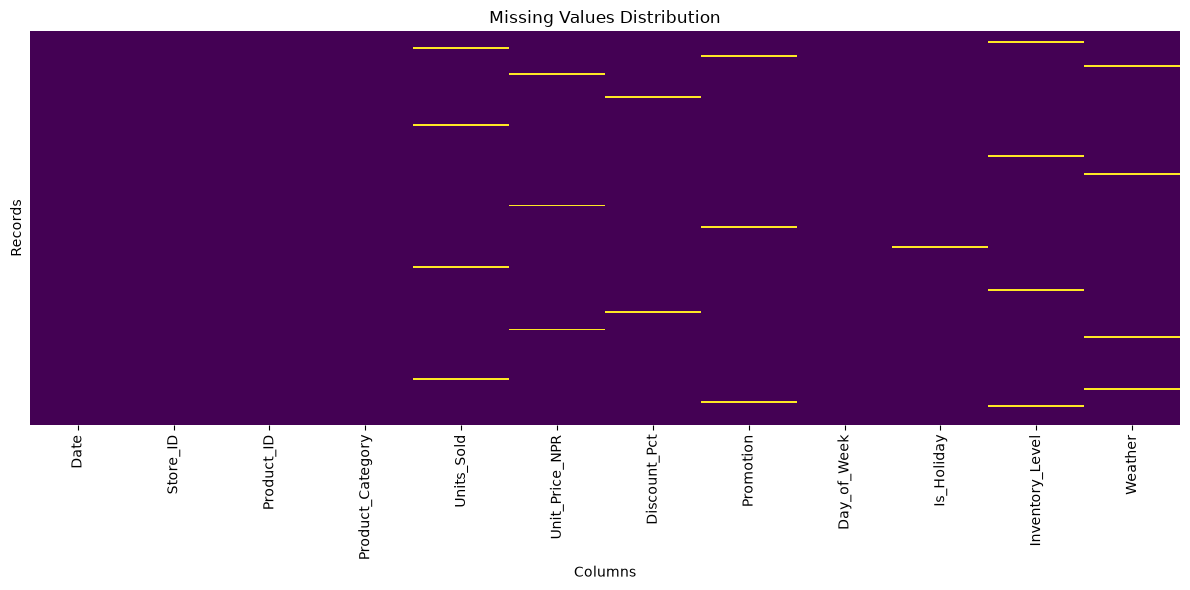

In [10]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Distribution")
plt.xlabel("Columns")
plt.ylabel("Records")
plt.tight_layout()
plt.show()

In [12]:

duplicate_rows = df.duplicated().sum()

duplicate_dates = df["Date"].duplicated().sum()

print("Duplicate Rows:", duplicate_rows)
print("Duplicate Dates (raw format):", duplicate_dates)

Duplicate Rows: 0
Duplicate Dates (raw format): 1


In [13]:
parsed_dates = pd.to_datetime(
    df["Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Invalid Dates:", parsed_dates.isna().sum())

print(
    "Duplicate Dates After Parsing:",
    parsed_dates.duplicated().sum()
)

Invalid Dates: 0
Duplicate Dates After Parsing: 2


In [14]:
categorical_columns = [
    "Store_ID",
    "Product_ID",
    "Product_Category",
    "Promotion",
    "Day_of_Week",
    "Weather"
]

for column in categorical_columns:

    print(f"\n{'='*40}")
    print(f"Column: {column}")
    print(f"{'='*40}")

    print(df[column].value_counts(dropna=False))


Column: Store_ID
Store_ID
ST-01       198
st-01         1
Store 01      1
Name: count, dtype: int64

Column: Product_ID
Product_ID
SKU-1001    198
sku-1001      1
SKU 1001      1
Name: count, dtype: int64

Column: Product_Category
Product_Category
Beverages    197
beverages      1
Drink          1
BEVERAGE       1
Name: count, dtype: int64

Column: Promotion
Promotion
No          149
Yes          44
NaN           3
Y             1
TRUE          1
No promo      1
1             1
Name: count, dtype: int64

Column: Day_of_Week
Day_of_Week
Thursday     29
Saturday     29
Friday       28
Sunday       28
Monday       28
Tuesday      28
Wednesday    27
thur          1
Saturday      1
Mon           1
Name: count, dtype: int64

Column: Weather
Weather
Cool     81
Mild     76
Warm     36
NaN       4
warm      1
Sunny     1
COLD      1
Name: count, dtype: int64


In [15]:
numeric_columns = [
    "Units_Sold",
    "Unit_Price_NPR",
    "Discount_Pct",
    "Is_Holiday",
    "Inventory_Level"
]

for column in numeric_columns:

    numeric_data = pd.to_numeric(
        df[column],
        errors="coerce"
    )

    print(f"\nColumn: {column}")
    print("Minimum:", numeric_data.min())
    print("Maximum:", numeric_data.max())
    print("Mean:", numeric_data.mean())
    print("Invalid / Non-numeric:",
          numeric_data.isna().sum())


Column: Units_Sold
Minimum: -7.0
Maximum: 999.0
Mean: 47.34871794871795
Invalid / Non-numeric: 5

Column: Unit_Price_NPR
Minimum: 0.0
Maximum: 9999.0
Mean: 169.61969387755104
Invalid / Non-numeric: 4

Column: Discount_Pct
Minimum: -10.0
Maximum: 125.0
Mean: 2.803030303030303
Invalid / Non-numeric: 2

Column: Is_Holiday
Minimum: 0.0
Maximum: 3.0
Mean: 0.04522613065326633
Invalid / Non-numeric: 1

Column: Inventory_Level
Minimum: -20.0
Maximum: 850.0
Mean: 59.05612244897959
Invalid / Non-numeric: 4


In [16]:
sales = pd.to_numeric(df["Units_Sold"], errors="coerce")
price = pd.to_numeric(df["Unit_Price_NPR"], errors="coerce")
discount = pd.to_numeric(df["Discount_Pct"], errors="coerce")
inventory = pd.to_numeric(df["Inventory_Level"], errors="coerce")
holiday = pd.to_numeric(df["Is_Holiday"], errors="coerce")

print("Negative Sales:", (sales < 0).sum())

print("Invalid Prices:", (price <= 0).sum())

print(
    "Invalid Discounts:",
    ((discount < 0) | (discount > 100)).sum()
)

print("Negative Inventory:", (inventory < 0).sum())

print(
    "Invalid Holiday Values:",
    (~holiday.isin([0, 1]) & holiday.notna()).sum()
)

Negative Sales: 1
Invalid Prices: 1
Invalid Discounts: 2
Negative Inventory: 1
Invalid Holiday Values: 1


In [17]:
# Temporarily parse dates
parsed_dates = pd.to_datetime(
    df["Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Earliest Date:", parsed_dates.min())
print("Latest Date:", parsed_dates.max())

print("Invalid Dates:", parsed_dates.isna().sum())

print(
    "Duplicate Parsed Dates:",
    parsed_dates.duplicated().sum()
)

Earliest Date: 2025-01-01 00:00:00
Latest Date: 2025-12-07 00:00:00
Invalid Dates: 0
Duplicate Parsed Dates: 2


In [18]:
df["Date"].value_counts().head(10)

Date
2025-07-16    2
2025-01-01    1
2025-01-02    1
2025-01-03    1
2025-01-04    1
2025-01-05    1
2025-01-06    1
2025-01-07    1
2025-01-08    1
2025-01-09    1
Name: count, dtype: int64

In [19]:
import os

output_path = data_path + r"\outputs"

os.makedirs(output_path, exist_ok=True)

missing_summary.to_csv(
    output_path + r"\missing_values_report.csv"
)

print("Missing value report saved successfully!")

Missing value report saved successfully!


## Data Cleaning

In [21]:
import pandas as pd
import numpy as np
import os

data_path = r"C:\Users\main\Desktop\Projects\Retail Demand Forecasting"

excel_path = data_path + r"\data\retail_demand_forecasting_raw_data.xlsx"

df = pd.read_excel(excel_path, sheet_name="Raw_Data")


df_clean = df.copy()

print("Raw dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Raw dataset shape: (200, 12)
Working dataset shape: (200, 12)


In [22]:
numeric_columns = [
    "Units_Sold",
    "Unit_Price_NPR",
    "Discount_Pct",
    "Is_Holiday",
    "Inventory_Level"
]

for column in numeric_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    )

In [23]:
categorical_columns = [
    "Store_ID",
    "Product_ID",
    "Product_Category",
    "Promotion",
    "Day_of_Week",
    "Weather"
]

for column in categorical_columns:

    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
    )

In [24]:
promotion_mapping = {
    "yes": "Yes",
    "y": "Yes",
    "true": "Yes",
    "1": "Yes",
    "no": "No",
    "no promo": "No",
    "false": "No",
    "0": "No"
}

df_clean["Promotion"] = (
    df_clean["Promotion"]
    .str.lower()
    .map(promotion_mapping)
)

In [25]:
df_clean["Store_ID"] = (
    df_clean["Store_ID"]
    .str.upper()
    .str.replace("STORE 01", "ST-01")
)

df_clean["Product_ID"] = (
    df_clean["Product_ID"]
    .str.upper()
    .str.replace("SKU 1001", "SKU-1001")
)

In [26]:
category_mapping = {
    "beverages": "Beverages",
    "drink": "Beverages",
    "beverage": "Beverages"
}

df_clean["Product_Category"] = (
    df_clean["Product_Category"]
    .str.lower()
    .map(category_mapping)
)

In [27]:
weather_mapping = {
    "warm": "Warm",
    "mild": "Mild",
    "cool": "Cool",
    "cold": "Cool",
    "sunny": "Warm"
}

df_clean["Weather"] = (
    df_clean["Weather"]
    .str.lower()
    .map(weather_mapping)
)

In [28]:
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Invalid dates:", df_clean["Date"].isna().sum())

Invalid dates: 0


In [29]:
df_clean = df_clean.dropna(subset=["Date"])

#### Handling duplicate records

In [30]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


In [31]:
df_clean = df_clean.drop_duplicates()

In [32]:
print(
    "Duplicate dates:",
    df_clean["Date"].duplicated().sum()
)

Duplicate dates: 2


In [37]:
duplicate_date_records = df_clean[
    df_clean["Date"].duplicated(keep=False)
].sort_values("Date")

duplicate_date_records

#as we can see in the below output, there are 4 dates which are duplicate. lets clean them first.

,Date,Store_ID,Product_ID,Product_Category,Units_Sold,Unit_Price_NPR,Discount_Pct,Promotion,Day_of_Week,Is_Holiday,Inventory_Level,Weather


In [38]:
df_clean = df_clean.drop_duplicates(
    subset=["Date"],
    keep="first"
)

## Handle invalid numerical values

In [39]:
# Negative sales
df_clean.loc[df_clean["Units_Sold"] < 0, "Units_Sold"] = np.nan

# Invalid prices
df_clean.loc[df_clean["Unit_Price_NPR"] <= 0, "Unit_Price_NPR"] = np.nan

# Invalid discounts
df_clean.loc[
    (df_clean["Discount_Pct"] < 0) |
    (df_clean["Discount_Pct"] > 100),
    "Discount_Pct"
] = np.nan

# Invalid inventory
df_clean.loc[df_clean["Inventory_Level"] < 0, "Inventory_Level"] = np.nan

# Invalid holiday indicators
df_clean.loc[
    ~df_clean["Is_Holiday"].isin([0, 1]),
    "Is_Holiday"
] = np.nan

#### Handling Missing values

In [40]:
missing_report = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().mean() * 100
    ).round(2)
})

missing_report.sort_values(
    by="Missing_Count",
    ascending=False
)

,Missing_Count,Missing_Percentage
Units_Sold,6,3.03
Unit_Price_NPR,5,2.53
Inventory_Level,5,2.53
Discount_Pct,4,2.02
Weather,4,2.02
Promotion,3,1.52
Is_Holiday,2,1.01
Date,0,0.00
Product_Category,0,0.00
Product_ID,0,0.00


In [42]:

df_clean["Unit_Price_NPR"] = (
    df_clean["Unit_Price_NPR"]
    .fillna(df_clean["Unit_Price_NPR"].median())
)

mask = (
    df_clean["Discount_Pct"].isna() &
    df_clean["Promotion"].eq("No")
)

df_clean.loc[mask, "Discount_Pct"] = 0


df_clean["Discount_Pct"] = (
    df_clean["Discount_Pct"]
    .fillna(df_clean["Discount_Pct"].median())
)


df_clean["Weather"] = df_clean["Weather"].fillna("Unknown")


df_clean["Inventory_Level"] = (
    df_clean["Inventory_Level"]
    .fillna(df_clean["Inventory_Level"].median())
)


### Reconstruct calendar variables

In [43]:
df_clean["Day_of_Week"] = (
    df_clean["Date"].dt.day_name()
)

df_clean["Day_of_Month"] = (
    df_clean["Date"].dt.day
)

df_clean["Month"] = (
    df_clean["Date"].dt.month
)

df_clean["Year"] = (
    df_clean["Date"].dt.year
)

df_clean["Weekend"] = (
    df_clean["Date"].dt.dayofweek >= 5
).astype(int)

In [44]:
df_clean = df_clean.sort_values(
    by="Date"
).reset_index(drop=True)

print(df_clean.head())
print(df_clean.tail())

        Date Store_ID Product_ID Product_Category  Units_Sold  Unit_Price_NPR  \
0 2025-01-01    ST-01   SKU-1001        Beverages        46.0          116.88   
1 2025-01-02    ST-01   SKU-1001        Beverages        51.0          121.07   
2 2025-01-03    ST-01   SKU-1001        Beverages        46.0          119.51   
3 2025-01-04    ST-01   SKU-1001        Beverages        42.0          121.15   
4 2025-01-05    ST-01   SKU-1001        Beverages        45.0          124.30   

   Discount_Pct Promotion Day_of_Week  Is_Holiday  Inventory_Level Weather  \
0          10.0       Yes   Wednesday         0.0             72.0    Cool   
1           0.0        No    Thursday         0.0             52.0    Mild   
2          10.0       Yes      Friday         0.0             55.0    Mild   
3           0.0        No    Saturday         0.0             44.0    Mild   
4           0.0        No      Sunday         1.0             67.0    Mild   

   Day_of_Month  Month  Year  Weekend  
0   

In [45]:
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nDuplicate Dates:")
print(df_clean["Date"].duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

Cleaned Dataset Shape: (198, 16)

Missing Values:
Date                0
Store_ID            0
Product_ID          0
Product_Category    0
Units_Sold          6
Unit_Price_NPR      0
Discount_Pct        0
Promotion           3
Day_of_Week         0
Is_Holiday          2
Inventory_Level     0
Weather             0
Day_of_Month        0
Month               0
Year                0
Weekend             0
dtype: int64

Duplicate Rows:
0

Duplicate Dates:
0

Data Types:
Date                datetime64[us]
Store_ID                    string
Product_ID                  string
Product_Category               str
Units_Sold                 float64
Unit_Price_NPR             float64
Discount_Pct               float64
Promotion                      str
Day_of_Week                    str
Is_Holiday                 float64
Inventory_Level            float64
Weather                        str
Day_of_Month                 int32
Month                        int32
Year                         int32
Weekend 

In [46]:
print("Missing Sales:", df_clean["Units_Sold"].isna().sum())

print("Negative Sales:",
      (df_clean["Units_Sold"] < 0).sum())

Missing Sales: 6
Negative Sales: 0


In [53]:
output_path = data_path + r"\outputs"

os.makedirs(output_path, exist_ok=True)

df_clean.to_csv(
    output_path + r"\retail_demand_forecasting_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
